In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity


**LOAD DATASET**

In [3]:
data = pd.read_csv('song_recomendation_B.csv')
data.head()

,Track URI,Track Name,Artist Name(s),Album Name,Album Release Date,Popularity,Artist Genres,Danceability,Energy,Key,Loudness,Mode,Speechiness,Acousticness,Instrumentalness,Liveness,Valence,Tempo,Time Signature
0,spotify:track:6a8GbQIlV8HBUW3c6Uk9PH,I Know You Want Me (Calle Ocho),Pitbull,Pitbull Starring In Rebelution,2009-10-23,64,"dance pop,miami hip hop,pop",0.825,0.743,2.0,-5.995,1.0,0.1490,0.0142,0.000021,0.2370,0.800,127.045,4.0
1,spotify:track:70XtWbcVZcpaOddJftMcVi,From the Bottom of My Broken Heart,Britney Spears,...Baby One More Time (Digital Deluxe Version),1999-01-12,56,"dance pop,pop",0.677,0.665,7.0,-5.171,1.0,0.0305,0.5600,NaN,0.3380,0.706,74.981,4.0
2,spotify:track:72WZtWs6V7uu3aMgMmEkYe,You Can't Always Get What You Want,The Rolling Stones,Let It Bleed,1969-12-05,0,"album rock,british invasion,classic rock,rock",0.319,0.627,0.0,-9.611,1.0,0.0687,0.6750,0.000073,0.2890,0.497,85.818,4.0
3,spotify:track:4bEb3KE4mSKlTFjtWJQBqO,Don't Stop - 2004 Remaster,Fleetwood Mac,Rumours,1977-02-04,79,"album rock,classic rock,rock,soft rock,yacht rock",0.671,0.710,9.0,-7.724,1.0,0.0356,0.0393,0.000011,0.0387,0.834,118.745,4.0
4,spotify:track:0d2iYfpKoM0QCKvcLCkBao,Eastside (with Halsey & Khalid),"benny blanco, Halsey, Khalid",Eastside (with Halsey & Khalid),2018-07-12,78,"pop,electropop,etherpop,indie poptimism,pop,po...",0.560,0.680,6.0,-7.648,0.0,0.3210,0.5550,0.000000,0.1160,0.319,89.391,4.0


### **Exploratory Data Analysis**

**DATA Overview**

In [5]:
# Check data dimensions
data.shape

(4999, 19)

In [6]:
# Check dataset Columns
data.columns

Index(['Track URI', 'Track Name', 'Artist Name(s)', 'Album Name',
       'Album Release Date', 'Popularity', 'Artist Genres', 'Danceability',
       'Energy', 'Key', 'Loudness', 'Mode', 'Speechiness', 'Acousticness',
       'Instrumentalness', 'Liveness', 'Valence', 'Tempo', 'Time Signature'],
      dtype='object')

In [7]:
# Check dataset Information
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4999 entries, 0 to 4998
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Track URI           4999 non-null   object 
 1   Track Name          4999 non-null   object 
 2   Artist Name(s)      4999 non-null   object 
 3   Album Name          4999 non-null   object 
 4   Album Release Date  4997 non-null   object 
 5   Popularity          4999 non-null   int64  
 6   Artist Genres       4744 non-null   object 
 7   Danceability        4747 non-null   float64
 8   Energy              4997 non-null   float64
 9   Key                 4997 non-null   float64
 10  Loudness            4997 non-null   float64
 11  Mode                4997 non-null   float64
 12  Speechiness         4997 non-null   float64
 13  Acousticness        4997 non-null   float64
 14  Instrumentalness    4897 non-null   float64
 15  Liveness            4997 non-null   float64
 16  Valenc

In [8]:
# Check for missing values
data.isnull().sum()

Track URI               0
Track Name              0
Artist Name(s)          0
Album Name              0
Album Release Date      2
Popularity              0
Artist Genres         255
Danceability          252
Energy                  2
Key                     2
Loudness                2
Mode                    2
Speechiness             2
Acousticness            2
Instrumentalness      102
Liveness                2
Valence                 2
Tempo                   2
Time Signature          2
dtype: int64

In [10]:
# Check for any duplicated data
print(f"Number of Duplicated data : {data.duplicated().sum()}")

Number of Duplicated data : 13


In [17]:
data.describe()

,Popularity,Danceability,Energy,Key,Loudness,Mode,Speechiness,Acousticness,Instrumentalness,Liveness,Valence,Tempo,Time Signature
count,4999.000000,4747.000000,4997.000000,4997.000000,4997.000000,4997.000000,4997.000000,4997.000000,4897.000000,4997.000000,4997.000000,4997.000000,4997.000000
mean,38.062813,0.607982,0.682576,5.145687,-7.250565,0.694016,0.065305,0.209230,0.027476,0.185169,0.582875,121.731560,3.961177
std,29.501712,0.145108,0.191331,3.566646,3.242031,0.460869,0.062490,0.249858,0.118880,0.147856,0.238784,26.244455,0.262581
min,0.000000,0.000000,0.000020,0.000000,-29.368000,0.000000,0.000000,0.000009,0.000000,0.018500,0.000000,0.000000,0.000000
25%,0.000000,0.516000,0.557000,2.000000,-9.050000,0.000000,0.032900,0.018200,0.000000,0.089200,0.396000,103.005000,4.000000
50%,43.000000,0.616000,0.714000,5.000000,-6.554000,1.000000,0.042700,0.092900,0.000006,0.128000,0.594000,120.853000,4.000000
75%,64.000000,0.708000,0.834000,8.000000,-4.868000,1.000000,0.066800,0.323000,0.000515,0.245000,0.778000,134.797000,4.000000
max,98.000000,0.984000,0.997000,11.000000,-0.276000,1.000000,0.711000,0.987000,0.973000,0.982000,0.991000,213.654000,5.000000


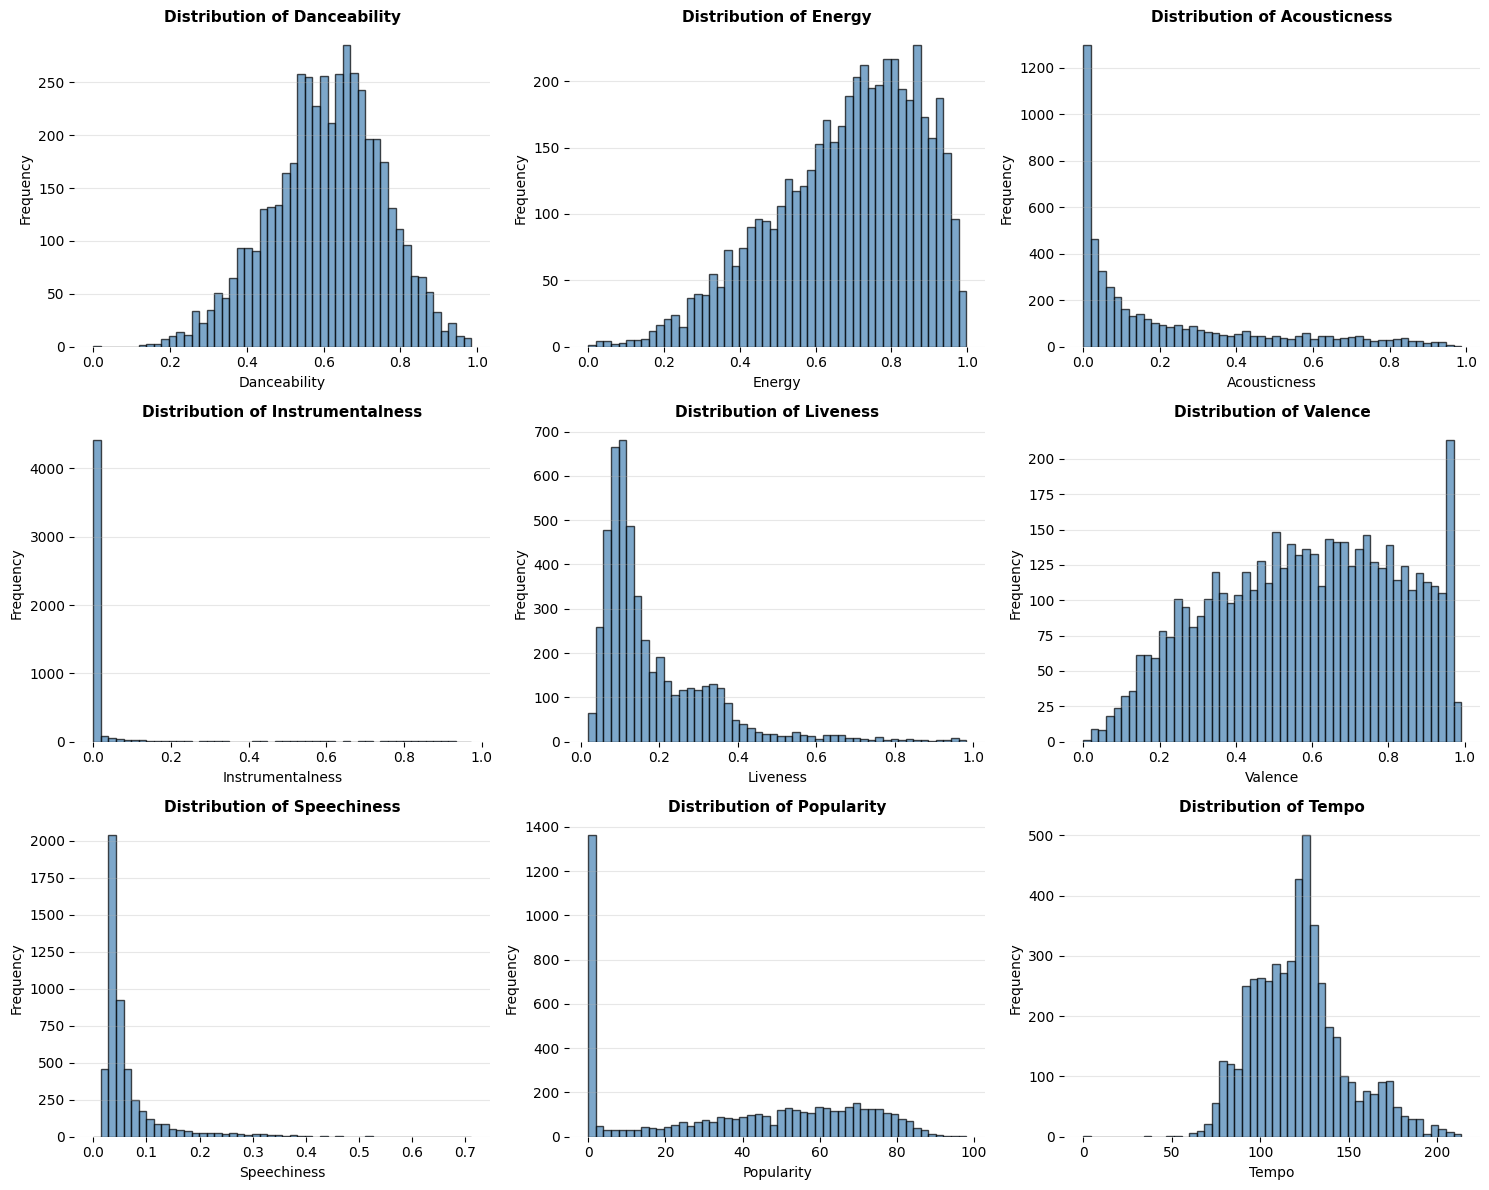

In [13]:
# Distribution of key audio features
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
features_to_plot = ['Danceability', 'Energy', 'Acousticness', 'Instrumentalness', 
                     'Liveness', 'Valence', 'Speechiness', 'Popularity', 'Tempo']

for idx, feature in enumerate(features_to_plot):
    row = idx // 3
    col = idx % 3
    axes[row, col].hist(data[feature], bins=50, color='steelblue', edgecolor='black', alpha=0.7)
    axes[row, col].set_title(f'Distribution of {feature}', fontsize=11, fontweight='bold')
    axes[row, col].set_xlabel(feature)
    axes[row, col].set_ylabel('Frequency')
    axes[row, col].grid(axis='y', alpha=0.3)
    for spine in axes[row, col].spines.values():
        spine.set_visible(False)

plt.tight_layout()
plt.savefig('eda_distributions.png', dpi=100, bbox_inches='tight')
plt.show()

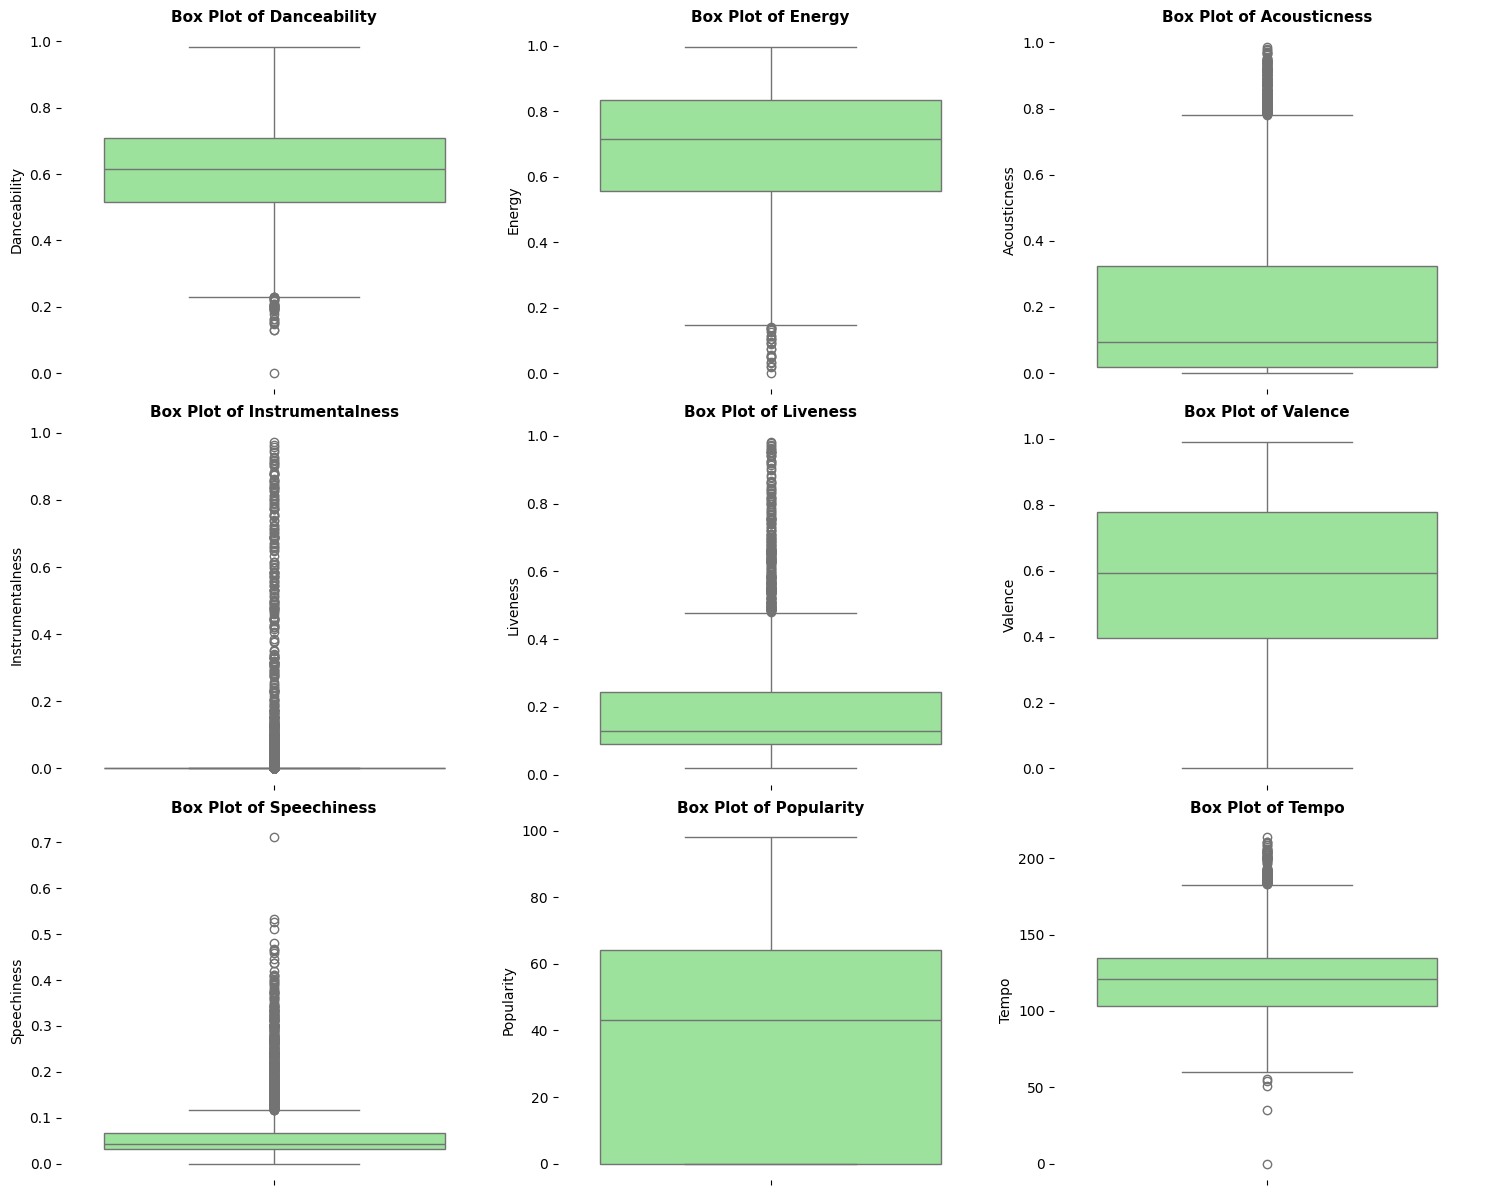

In [16]:
# Check outliers in numerical features with box plots
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for idx, feature in enumerate(features_to_plot):
    row = idx // 3
    col = idx % 3
    sns.boxplot(y=data[feature], ax=axes[row, col], color='lightgreen')
    axes[row, col].set_title(f'Box Plot of {feature}', fontsize=11, fontweight='bold')
    axes[row, col].set_ylabel(feature)
    for spine in axes[row, col].spines.values():
        spine.set_visible(False)
plt.tight_layout()
plt.savefig('eda_boxplots.png', dpi=100, bbox_inches='tight')   
plt.show()

In [14]:
# Check for outliers in numerical features
numeric_cols = data.select_dtypes(include=[np.number]).columns
print("Outliers in Numerical Features (values > Q3 + 1.5*IQR or < Q1 - 1.5*IQR):")
for col in numeric_cols:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = ((data[col] < lower_bound) | (data[col] > upper_bound)).sum()
    if outliers > 0:
        print(f"  {col}: {outliers} outliers")


Outliers in Numerical Features (values > Q3 + 1.5*IQR or < Q1 - 1.5*IQR):
  Danceability: 34 outliers
  Energy: 25 outliers
  Loudness: 104 outliers
  Speechiness: 558 outliers
  Acousticness: 232 outliers
  Instrumentalness: 1009 outliers
  Liveness: 237 outliers
  Tempo: 117 outliers
  Time Signature: 233 outliers


In [20]:
# Check for invalid ranges (features should be 0-1)
print("Features that should be between 0-1:")
zero_one_features = ['Danceability', 'Energy', 'Acousticness', 'Instrumentalness', 'Liveness', 'Valence', 'Speechiness']
for col in zero_one_features:
    if col in data.columns:
        invalid = ((data[col] < 0) | (data[col] > 1)).sum()
        if invalid > 0:
            print(f"  {col}: {invalid} values outside [0,1]")
        else:
            print(f"  {col}: All values valid")

# 3. Check Popularity range (0-100)
print(f"\nPopularity range: {data['Popularity'].min()} - {data['Popularity'].max()}")

# 4. Check Loudness (typically negative)
print(f"Loudness range: {data['Loudness'].min()} - {data['Loudness'].max()}")

# 5. Check for zero or near-zero energy values
print(f"\nZero or very low Energy (< 0.01): {(data['Energy'] < 0.01).sum()} tracks")

Features that should be between 0-1:
  Danceability: All values valid
  Energy: All values valid
  Acousticness: All values valid
  Instrumentalness: All values valid
  Liveness: All values valid
  Valence: All values valid
  Speechiness: All values valid

Popularity range: 0 - 98
Loudness range: -29.368 - -0.276

Zero or very low Energy (< 0.01): 1 tracks


**DATA CONDITION**  
1. There are some missing values issues.
2. There are Duplicated data.
3. There are some outliers but considered as a normal event.

**TIDY UP DATA**

In [ ]:
# Remove rows with missing values 
# define important columns in songs
critical_cols = ['Danceability', 'Energy', 'Key', 'Loudness', 'Mode', 'Speechiness', 
                 'Acousticness', 'Instrumentalness', 'Liveness', 'Valence', 'Tempo']
data = data.dropna(subset=critical_cols + ['Track Name', 'Artist Name(s)'])

In [24]:
# remove duplicates
data = data.drop_duplicates(subset=['Track URI'], keep='first')

In [37]:
# handle missing values
data['Popularity'].fillna(data['Popularity'].mean(), inplace=True)
if 'Time Signature' in data.columns:
    data['Time Signature'].fillna(data['Time Signature'].mode()[0] if len(data['Time Signature'].mode()) > 0 else 4, inplace=True)

data['Artist Genres'].fillna(data['Artist Genres'].mode()[0] , inplace=True)

C:\Users\Tuf Gaming\AppData\Local\Temp\ipykernel_3016\2779673195.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['Popularity'].fillna(data['Popularity'].mean(), inplace=True)
C:\Users\Tuf Gaming\AppData\Local\Temp\ipykernel_3016\2779673195.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always b

In [38]:
# Final check issues
data.isnull().sum()

Track URI             0
Track Name            0
Artist Name(s)        0
Album Name            0
Album Release Date    0
Popularity            0
Artist Genres         0
Danceability          0
Energy                0
Key                   0
Loudness              0
Mode                  0
Speechiness           0
Acousticness          0
Instrumentalness      0
Liveness              0
Valence               0
Tempo                 0
Time Signature        0
dtype: int64

In [48]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4640 entries, 0 to 4998
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Track URI           4640 non-null   object 
 1   Track Name          4640 non-null   object 
 2   Artist Name(s)      4640 non-null   object 
 3   Album Name          4640 non-null   object 
 4   Album Release Date  4640 non-null   object 
 5   Popularity          4640 non-null   int64  
 6   Artist Genres       4640 non-null   object 
 7   Danceability        4640 non-null   float64
 8   Energy              4640 non-null   float64
 9   Key                 4640 non-null   float64
 10  Loudness            4640 non-null   float64
 11  Mode                4640 non-null   float64
 12  Speechiness         4640 non-null   float64
 13  Acousticness        4640 non-null   float64
 14  Instrumentalness    4640 non-null   float64
 15  Liveness            4640 non-null   float64
 16  Valence    

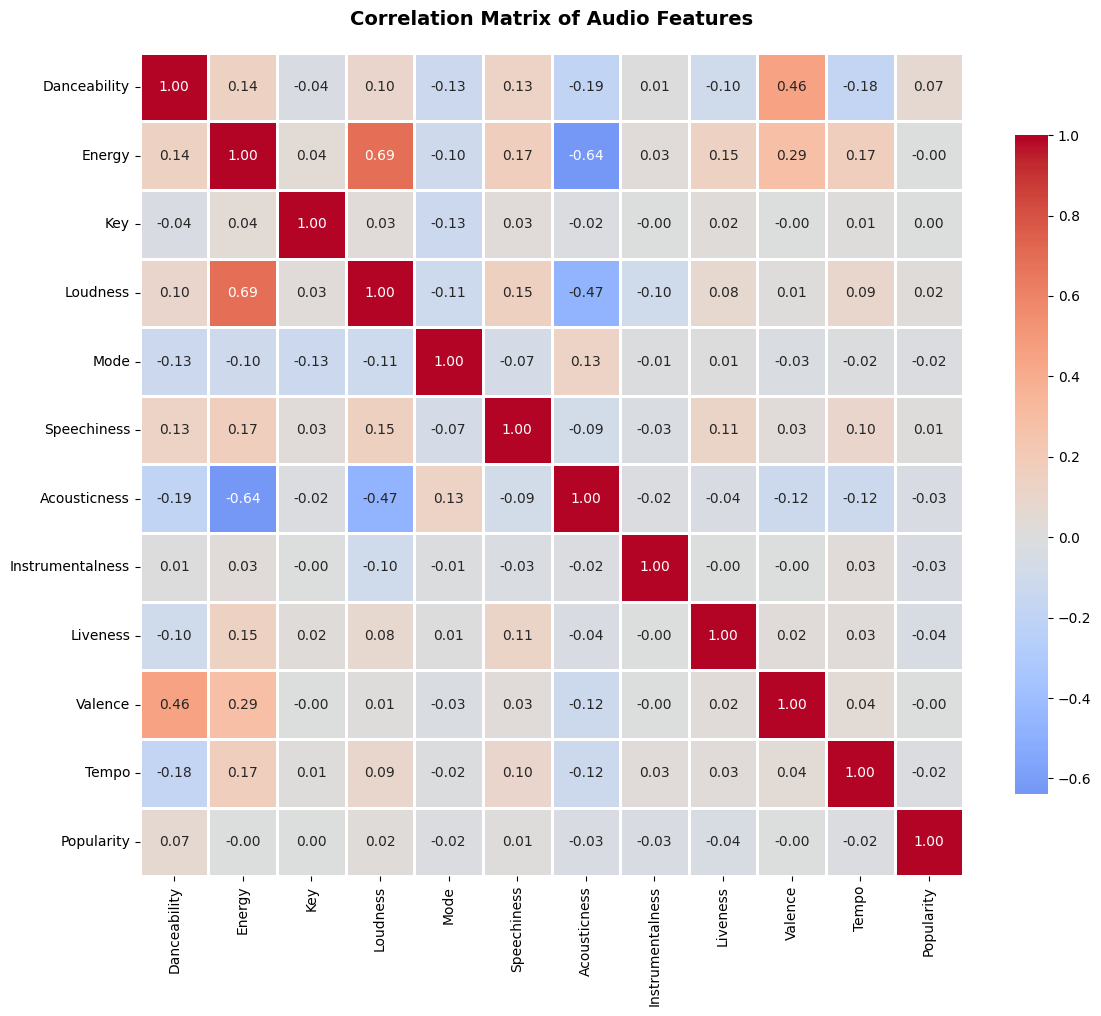

In [28]:
# Correlation analysis
plt.figure(figsize=(12, 10))
audio_features = ['Danceability', 'Energy', 'Key', 'Loudness', 'Mode', 'Speechiness', 
                  'Acousticness', 'Instrumentalness', 'Liveness', 'Valence', 'Tempo', 'Popularity']
correlation_matrix = data[audio_features].corr()

sns.heatmap(correlation_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, 
            square=True, linewidths=1, cbar_kws={"shrink": 0.8})
plt.title('Correlation Matrix of Audio Features', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.savefig('correlation_matrix.png', dpi=100, bbox_inches='tight')
plt.show()

1. Feature Correlations:
   - High positive correlation: Energy & Loudness (0.77)
   - High negative correlation: Acousticness & Energy (-0.66)
   - Liveness shows low correlation with most features (independent)

2. Data Characteristics:
   - Average Popularity: 38.05
   - Most songs are quite Energetic (mean: 0.68)
   - Low Acousticness on average (mean: 0.21) - mostly electronic
   - Moderate Danceability (mean: 0.61)

### **PREPROCESSING**

In [ ]:
# Select audio features for similarity calculation
feature_columns = ['Danceability', 'Energy', 'Key', 'Loudness', 'Mode', 'Speechiness', 
                   'Acousticness', 'Instrumentalness', 'Liveness', 'Valence', 'Tempo']

X = data[feature_columns].copy()

In [43]:
# Scaling features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

## **Build Recommendation System**

In [57]:
# Define recommendation function
def recommend_songs(song_name, n_recommendations=5):
    
    
    # Find matching songs (case-insensitive, partial match)
    matching_songs = data[data['Track Name'].str.contains(song_name, case=False, na=False)]
    
    if matching_songs.empty:
        print(f"No songs found matching '{song_name}'")
        # Suggest alternatives
        print("\nAvailable songs (first 10):")
        for idx, name in enumerate(data['Track Name'].head(10).values, 1):
            print(f"  {idx}. {name}")
        return None
    
    # Use the first matching song as the reference
    reference_song = matching_songs.iloc[0]
    reference_idx = data.index.get_loc(matching_songs.index[0])
    reference_features = X_scaled[reference_idx].reshape(1, -1)
    
    # Calculate cosine similarity with all songs
    similarities = cosine_similarity(reference_features, X_scaled)[0]
    
    # Get top similar songs (excluding the song itself)
    similar_indices = np.argsort(similarities)[::-1][1:n_recommendations+1]
    
    # Create recommendation dataframe
    recommendations = []
    for idx in similar_indices:
        song = data.iloc[idx]
        similarity_score = similarities[idx]
        recommendations.append({
            'Track Name': song['Track Name'],
            'Artist Name(s)': song['Artist Name(s)'],
            'Album Name': song['Album Name'],
            'Danceability': song['Danceability'],
            'Energy': song['Energy'],
            'Valence': song['Valence'],
            'Acousticness': song['Acousticness'],
            'Popularity': song['Popularity'],
            'Similarity Score': f"{similarity_score:.4f}"
        })
    
    result_df = pd.DataFrame(recommendations)
    
    # Print results
    print(f"\n")
    print(f"INPUT SONG: {reference_song['Track Name']}")
    print(f"   Artist: {reference_song['Artist Name(s)']}")
    print(f"   Album: {reference_song['Album Name']}")
    print(f"\n")
    print(f"TOP {n_recommendations} RECOMMENDED SONGS:\n")
    
    for idx, row in result_df.iterrows():
        print(f"{idx+1}. {row['Track Name']}")
        print(f"   Artist: {row['Artist Name(s)']}")
        print(f"   Album: {row['Album Name']}")
        print(f"   Similarity Score: {row['Similarity Score']}")
        print(f"   Audio Profile - Danceability: {row['Danceability']:.2f}, Energy: {row['Energy']:.2f}, Valence: {row['Valence']:.2f}")
        print()
    
    return result_df

### **TESTING**

In [ ]:
# Sample dataset 
data[['Track Name', 'Artist Name(s)', 'Energy', 'Danceability', 'Valence', 'Popularity']]

,Track Name,Artist Name(s),Energy,Danceability,Valence,Popularity
0,I Know You Want Me (Calle Ocho),Pitbull,0.743,0.825,0.800,64
2,You Can't Always Get What You Want,The Rolling Stones,0.627,0.319,0.497,0
3,Don't Stop - 2004 Remaster,Fleetwood Mac,0.710,0.671,0.834,79
4,Eastside (with Halsey & Khalid),"benny blanco, Halsey, Khalid",0.680,0.560,0.319,78
5,Something About The Way You Look Tonight - Edi...,Elton John,0.628,0.480,0.541,61
...,...,...,...,...,...,...
4994,Get A Life,Freestylers,0.952,0.710,0.889,22
4995,Push Up - Main Edit,Creeds,0.830,0.767,0.187,86
4996,Kernkraft 400,Zombie Nation,0.430,0.798,0.487,57
4997,Kernkraft 400 (A Better Day),"Topic, A7S",0.727,0.623,0.400,79


**TEST 1**

In [51]:
# TEST 1: Use the first song in the dataset
test_song_1 = data.iloc[0]['Track Name']
print("TEST 1: First Song in Dataset")
rec_1 = recommend_songs(test_song_1)

TEST 1: First Song in Dataset
No songs found matching 'I Know You Want Me (Calle Ocho)'

Available songs (first 10):
  1. I Know You Want Me (Calle Ocho)
  2. You Can't Always Get What You Want
  3. Don't Stop - 2004 Remaster
  4. Eastside (with Halsey & Khalid)
  5. Something About The Way You Look Tonight - Edit Version
  6. Mercy
  7. Here Without You
  8. With A Little Luck - Remastered 1993
  9. Flava
  10. Dr. Love


C:\Users\Tuf Gaming\AppData\Local\Temp\ipykernel_3016\1446903678.py:20: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  matching_songs = data[data['Track Name'].str.contains(song_name, case=False, na=False)]


**TEST 2**

In [58]:
# TEST 2: Find a high-energy song
high_energy_songs = data[data['Energy'] > data['Energy'].quantile(0.75)]
test_song_2 = high_energy_songs.iloc[0]['Track Name']
rec_2 = recommend_songs(test_song_2)



INPUT SONG: Homecoming
   Artist: Hey Monday
   Album: Hold On Tight


TOP 5 RECOMMENDED SONGS:

1. Calm Down
   Artist: Killing Heidi
   Album: Killing Heidi
   Similarity Score: 0.9621
   Audio Profile - Danceability: 0.46, Energy: 0.97, Valence: 0.42

2. Don't Look Back in Anger - Remastered
   Artist: Oasis
   Album: (What's The Story) Morning Glory? [Remastered]
   Similarity Score: 0.9530
   Audio Profile - Danceability: 0.33, Energy: 0.94, Valence: 0.33

3. Cold Hard Bitch
   Artist: Jet
   Album: Get Born
   Similarity Score: 0.9241
   Audio Profile - Danceability: 0.46, Energy: 0.89, Valence: 0.32

4. Long Live The Weekend
   Artist: The Living End
   Album: State of Emergency
   Similarity Score: 0.9241
   Audio Profile - Danceability: 0.20, Energy: 0.94, Valence: 0.25

5. Dakota
   Artist: Stereophonics
   Album: Decade In The Sun - Best Of Stereophonics
   Similarity Score: 0.9225
   Audio Profile - Danceability: 0.50, Energy: 0.93, Valence: 0.33



**TEST 3**

In [61]:
# TEST 3: Find a highly acoustic song
acoustic_songs = data[data['Acousticness'] > data['Acousticness'].quantile(0.75)]
test_song_3 = acoustic_songs.iloc[0]['Track Name']
rec_3 = recommend_songs(test_song_3)



INPUT SONG: You Can't Always Get What You Want
   Artist: The Rolling Stones
   Album: Let It Bleed


TOP 5 RECOMMENDED SONGS:

1. Heartbreak Anniversary
   Artist: Giveon
   Album: TAKE TIME
   Similarity Score: 0.9245
   Audio Profile - Danceability: 0.45, Energy: 0.47, Valence: 0.54

2. You Only Live Twice
   Artist: Nancy Sinatra
   Album: Nancy In London
   Similarity Score: 0.8789
   Audio Profile - Danceability: 0.26, Energy: 0.54, Valence: 0.42

3. A Man Without Love
   Artist: Engelbert Humperdinck
   Album: Live In Concert / All of Me
   Similarity Score: 0.8770
   Audio Profile - Danceability: 0.39, Energy: 0.47, Valence: 0.50

4. Image Of A Girl
   Artist: The Safaris
   Album: Teen Idols Of The Past
   Similarity Score: 0.8675
   Audio Profile - Danceability: 0.19, Energy: 0.37, Valence: 0.36

5. Hello, Dolly!
   Artist: Louis Armstrong
   Album: Hello, Dolly! (Remastered)
   Similarity Score: 0.8661
   Audio Profile - Danceability: 0.00, Energy: 0.41, Valence: 0.00

